In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPool2D, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import confusion_matrix

In [2]:
# Load Fashion-MNIST dataset
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Normalize pixel values to [0, 1]
X_train = X_train / 255.0
X_test = X_test / 255.0

# Add channel dimension for CNN: (N, 28, 28, 1)
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Print shapes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
X_train shape: (60000, 28, 28, 1)
X_test shape: (10000, 28, 28, 1)
y_train shape: (60000,)
y_test shape: (10000,)


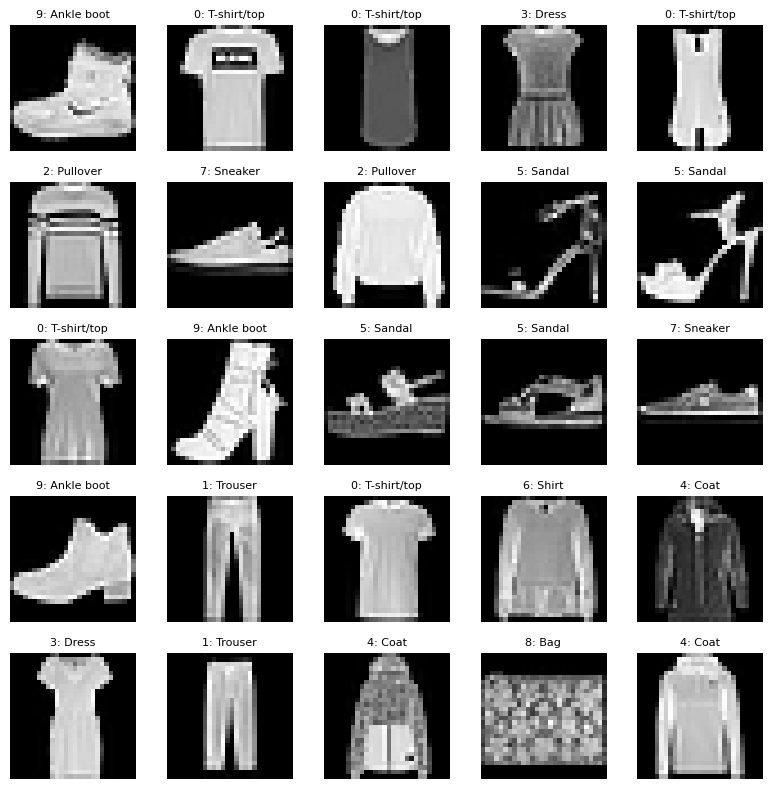

In [3]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

plt.figure(figsize=(8, 8))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="gray")
    plt.title(str(y_train[i]) + ": " + class_names[y_train[i]], fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
unique_classes, class_counts = np.unique(y_train, return_counts=True)

print("Class distribution in training set:")
for cls, count in zip(unique_classes, class_counts):
    print(cls, class_names[cls], ":", count)

if np.all(class_counts == class_counts[0]):
    print("The training set is balanced.")
else:
    print("The training set is not perfectly balanced.")

Class distribution in training set:
0 T-shirt/top : 6000
1 Trouser : 6000
2 Pullover : 6000
3 Dress : 6000
4 Coat : 6000
5 Sandal : 6000
6 Shirt : 6000
7 Sneaker : 6000
8 Bag : 6000
9 Ankle boot : 6000
The training set is balanced.


The class distribution shows that each class has 6000 training images. Since all classes have the same number of samples, the training set is balanced.

In [5]:
model_mlp = Sequential([
    Flatten(input_shape=(28, 28, 1)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

model_mlp.compile(
    optimizer=Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_mlp = model_mlp.fit(
    X_train,
    y_train,
    epochs=15,
    validation_split=0.1
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8212 - loss: 0.5030 - val_accuracy: 0.8552 - val_loss: 0.4045
Epoch 2/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8655 - loss: 0.3690 - val_accuracy: 0.8718 - val_loss: 0.3720
Epoch 3/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8773 - loss: 0.3333 - val_accuracy: 0.8743 - val_loss: 0.3587
Epoch 4/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8857 - loss: 0.3094 - val_accuracy: 0.8770 - val_loss: 0.3446
Epoch 5/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8909 - loss: 0.2955 - val_accuracy: 0.8818 - val_loss: 0.3408
Epoch 6/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8951 - loss: 0.2801 - val_accuracy: 0.8820 - val_loss: 0.3212
Epoch 7/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9007 - loss: 0.2653 - val_accuracy: 0.8743 - val_loss: 0.3424
Epoch 8/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9039 - loss: 0.2577 - 

In [6]:
mlp_param_count = model_mlp.count_params()

mlp_train_loss, acc_mlp_train = model_mlp.evaluate(X_train, y_train, verbose=0)
mlp_test_loss, acc_mlp_test = model_mlp.evaluate(X_test, y_test, verbose=0)

print("MLP parameter count:", mlp_param_count)
print("MLP training accuracy:", acc_mlp_train)
print("MLP test accuracy:", acc_mlp_test)

model_mlp.summary()

MLP parameter count: 109386
MLP training accuracy: 0.9264666438102722
MLP test accuracy: 0.8863999843597412


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 328,160 (1.25 MB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 218,774 (854.59 KB)

The MLP has 109,386 trainable parameters. It achieved a training accuracy of 92.65% and a test accuracy of 88.64%.

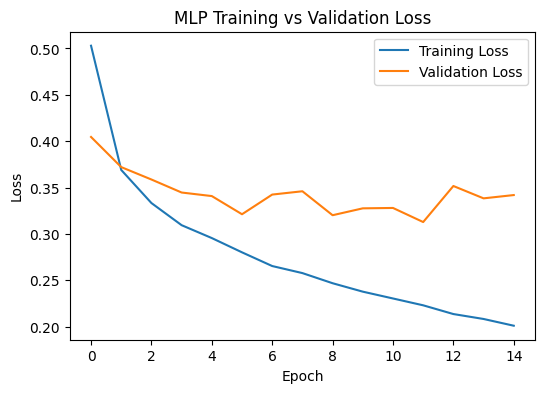

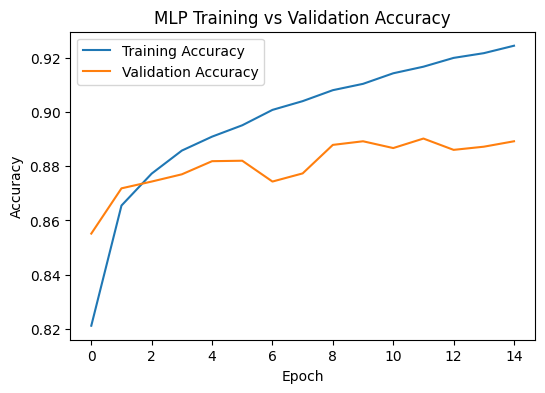

In [7]:
plt.figure(figsize=(6, 4))
plt.plot(history_mlp.history["loss"], label="Training Loss")
plt.plot(history_mlp.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP Training vs Validation Loss")
plt.legend()
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(history_mlp.history["accuracy"], label="Training Accuracy")
plt.plot(history_mlp.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MLP Training vs Validation Accuracy")
plt.legend()
plt.show()

The MLP training loss decreases steadily over the 15 epochs, and the training accuracy continues to increase. However, the validation loss decreases at the beginning and then starts to fluctuate, while the validation accuracy becomes almost stable around epochs 8–10. This suggests slight overfitting because the model keeps improving on the training data, but the validation performance does not improve much after that point.

In [8]:
model_cnn = Sequential([
    Conv2D(32, (3, 3), activation="relu", padding="same", input_shape=(28, 28, 1)),
    MaxPool2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPool2D((2, 2)),

    GlobalAveragePooling2D(),
    Dense(10, activation="softmax")
])

model_cnn.compile(
    optimizer=Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_cnn = model_cnn.fit(
    X_train,
    y_train,
    epochs=15,
    validation_split=0.1
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.6067 - loss: 1.1352 - val_accuracy: 0.7198 - val_loss: 0.8053
Epoch 2/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7372 - loss: 0.7429 - val_accuracy: 0.7637 - val_loss: 0.6632
Epoch 3/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7697 - loss: 0.6521 - val_accuracy: 0.7725 - val_loss: 0.6451
Epoch 4/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7888 - loss: 0.5952 - val_accuracy: 0.7705 - val_loss: 0.6110
Epoch 5/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8033 - loss: 0.5564 - val_accuracy: 0.8192 - val_loss: 0.5195
Epoch 6/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8156 - loss: 0.5239 - val_accuracy: 0.8193 - val_loss: 0.5033
Epoch 7/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8264 - loss: 0.4967 - val_accuracy: 0.8245 - val_loss: 0.4894
Epoch 8/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8329 - loss: 0.4764 -

In [9]:
cnn_param_count = model_cnn.count_params()

cnn_train_loss, acc_cnn_train = model_cnn.evaluate(X_train, y_train, verbose=0)
cnn_test_loss, acc_cnn_test = model_cnn.evaluate(X_test, y_test, verbose=0)

print("CNN parameter count:", cnn_param_count)
print("CNN training accuracy:", acc_cnn_train)
print("CNN test accuracy:", acc_cnn_test)

model_cnn.summary()

CNN parameter count: 19466
CNN training accuracy: 0.8739166855812073
CNN test accuracy: 0.8639000058174133


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,400 (228.13 KB)

 Trainable params: 19,466 (76.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 38,934 (152.09 KB)

The CNN has 19,466 trainable parameters. It achieved a training accuracy of 87.39% and a test accuracy of 86.39%. The training and test accuracies are close, which means the CNN does not show strong overfitting.

In [10]:
print("CNN output volume sizes:")
print("Input: 28 x 28 x 1")
print("After Conv2D 1: 28 x 28 x 32")
print("After MaxPool2D 1: 14 x 14 x 32")
print("After Conv2D 2: 14 x 14 x 64")
print("After MaxPool2D 2: 7 x 7 x 64")
print("After GlobalAveragePooling2D: 64")
print("After Dense output layer: 10")

CNN output volume sizes:
Input: 28 x 28 x 1
After Conv2D 1: 28 x 28 x 32
After MaxPool2D 1: 14 x 14 x 32
After Conv2D 2: 14 x 14 x 64
After MaxPool2D 2: 7 x 7 x 64
After GlobalAveragePooling2D: 64
After Dense output layer: 10


For the first convolutional layer:

parameters = (filter_height × filter_width × input_channels + 1) × num_filters

= (3 × 3 × 1 + 1) × 32  
= (9 + 1) × 32  
= 10 × 32  
= 320 parameters

This matches the parameter count reported by the model summary for the first Conv2D layer.

Output volume sizes:

Input: 28 × 28 × 1

First Conv2D uses padding='same', filter size 3, stride 1, and P = 1:

W₂ = (W₁ − F + 2P) / S + 1  
W₂ = (28 − 3 + 2(1)) / 1 + 1 = 28

So after Conv2D 1: 28 × 28 × 32

After MaxPool2D with filter size 2 and stride 2:

W₂ = (28 − 2) / 2 + 1 = 14

So after MaxPool2D 1: 14 × 14 × 32

Second Conv2D also uses padding='same', so the spatial size stays the same:

W₂ = (14 − 3 + 2(1)) / 1 + 1 = 14

So after Conv2D 2: 14 × 14 × 64

After MaxPool2D 2:

W₂ = (14 − 2) / 2 + 1 = 7

So after MaxPool2D 2: 7 × 7 × 64

GlobalAveragePooling2D averages each 7 × 7 feature map into one value per channel, producing a vector of length 64.

After GAP: 64

Final Dense layer gives 10 class probabilities.

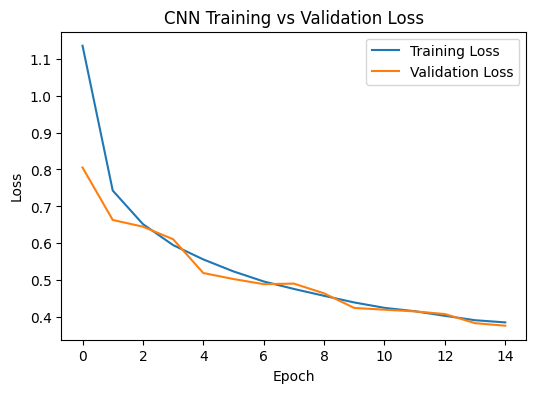

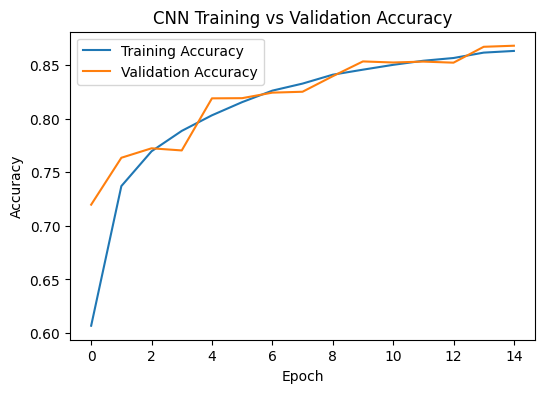

In [11]:
plt.figure(figsize=(6, 4))
plt.plot(history_cnn.history["loss"], label="Training Loss")
plt.plot(history_cnn.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training vs Validation Loss")
plt.legend()
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(history_cnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_cnn.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training vs Validation Accuracy")
plt.legend()
plt.show()

The CNN training and validation loss both decrease steadily over the 15 epochs. The training and validation accuracy also increase together and stay close to each other. This shows that the CNN is learning well without strong overfitting. The validation accuracy becomes almost stable around epochs 10–14.

In [12]:
y_pred_probs = model_cnn.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

cm_cnn = confusion_matrix(y_test, y_pred)

print("CNN confusion matrix:")
print(cm_cnn)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
CNN confusion matrix:
[[734   0  23  68  11   0 150   0  14   0]
 [  0 961   4  23   6   0   4   0   2   0]
 [ 19   1 808   8  64   0  98   0   2   0]
 [ 16   8  11 885  26   0  51   0   3   0]
 [  0   2  70  52 760   0 115   0   1   0]
 [  0   0   0   0   0 946   1  38   6   9]
 [ 86   5  61  42 103   0 692   0  11   0]
 [  0   0   0   0   0  10   0 961   4  25]
 [  1   1  13   3   4   4  12   2 956   4]
 [  0   0   1   2   2  10   0  46   3 936]]


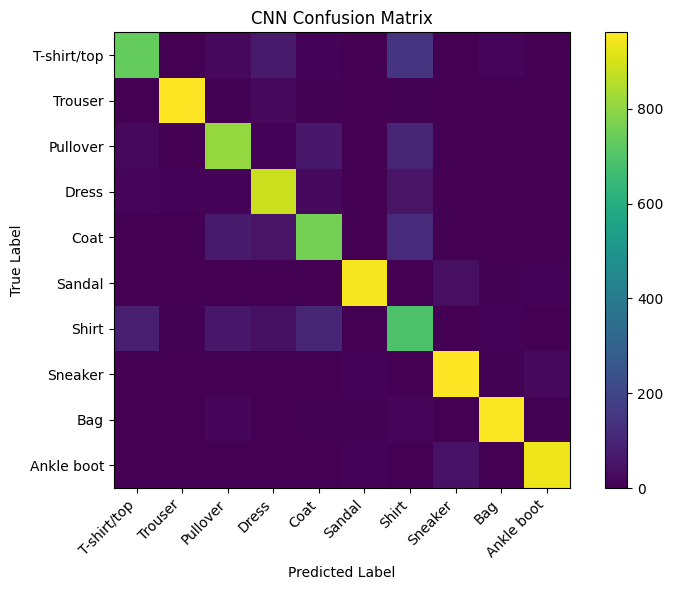

In [13]:
plt.figure(figsize=(8, 6))
plt.imshow(cm_cnn)
plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.colorbar()

plt.xticks(np.arange(10), class_names, rotation=45, ha="right")
plt.yticks(np.arange(10), class_names)

plt.tight_layout()
plt.show()

The CNN confusion matrix shows that most predictions are on the diagonal, which means many test images were classified correctly. The heatmap also shows some off diagonal errors, especially between visually similar clothing classes. The strongest confusion appears between upper-body clothing items such as T-shirt/top, Shirt, and Coat.

In [14]:
cm_without_diagonal = cm_cnn.copy()
np.fill_diagonal(cm_without_diagonal, 0)

confusions = []

for i in range(10):
    for j in range(10):
        if i != j:
            confusions.append((cm_without_diagonal[i, j], i, j))

confusions = sorted(confusions, reverse=True)

print("Two most-confused class pairs:")
for value, true_class, predicted_class in confusions[:2]:
    print(
        class_names[true_class],
        "was predicted as",
        class_names[predicted_class],
        ":",
        value,
        "times"
    )

Two most-confused class pairs:
T-shirt/top was predicted as Shirt : 150 times
Coat was predicted as Shirt : 115 times


The two most-confused class pairs are T-shirt/top predicted as Shirt 150 times, and Coat predicted as Shirt 115 times. This makes sense visually because T-shirt/top, Shirt, and Coat are all upper-body clothing classes. In 28×28 grayscale images, their sleeves, outlines, and overall shapes can look very similar, so the CNN may confuse them.

In [15]:
accuracy_gap = acc_cnn_test - acc_mlp_test
parameter_ratio = mlp_param_count / cnn_param_count

mlp_cost_per_accuracy = mlp_param_count / (acc_mlp_test * 100)
cnn_cost_per_accuracy = cnn_param_count / (acc_cnn_test * 100)

print("Accuracy gap:", accuracy_gap)
print("Parameter ratio MLP/CNN:", parameter_ratio)
print("MLP parameter cost per percentage point of test accuracy:", mlp_cost_per_accuracy)
print("CNN parameter cost per percentage point of test accuracy:", cnn_cost_per_accuracy)

Accuracy gap: -0.02249997854232788
Parameter ratio MLP/CNN: 5.61933627863968
MLP parameter cost per percentage point of test accuracy: 1234.0478557094177
CNN parameter cost per percentage point of test accuracy: 225.32700392311574


In this run, the MLP achieved 88.64% test accuracy, while the CNN achieved 86.39%. The accuracy gap is -2.25 percentage points, so the MLP performed slightly better in accuracy. However, the MLP has 109,386 parameters, while the CNN has only 19,466 parameters. The parameter ratio is 5.62, meaning the MLP uses about 5.62 times more parameters than the CNN. The parameter cost per percentage point of test accuracy is 1234.05 for the MLP and 225.33 for the CNN, so the CNN is more parameter-efficient. CNNs are useful for images because they use local connectivity, parameter sharing, and pooling, which help them learn visual patterns with fewer parameters. Pooling also gives some translation invariance when objects shift slightly in the image. An MLP may be better for simple tabular data because there is no spatial structure that needs convolution.